# Pauli twirling

This experiment asks whether random Pauli gates around native two-qubit gates improve the sampled QAOA results for the fixed problem. The baseline and twirled runs use the same routed circuits, angles, backend noise snapshot, and total number of shots.

Pauli twirling keeps each gate's ideal action while randomizing how its noise accumulates. It is mainly useful against coherent errors; this FakeManilaV2 model is a simulation snapshot and may not reproduce those errors. A second backend is left for a later comparison.

## 1. Load the shared problem

This loads the same reads, fixed angles, circuit builder, FakeManilaV2 backend and scoring function used by the other experiment notebooks. Angles are held fixed; this test does not train the circuit.

In [1]:
from pathlib import Path
from qiskit.circuit import pauli_twirl_2q_gates
import qiskit

setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

print('Qiskit version:', qiskit.__version__)
print('Backend:', backend.name)
print('Shots per comparison:', shots)

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.
Qiskit version: 2.5.0
Backend: fake_manila
Shots per comparison: 2048


## 2. Compile the common baseline

First compile the original measured circuit onto the same physical layout for each transpiler seed. Twirling is applied after routing, so it does not change the router's choices or the two-qubit gate count.

In [2]:
num_randomizations = 16
if shots % num_randomizations:
    raise ValueError('Choose a shot budget divisible by the randomization count.')
shots_per_randomization = shots // num_randomizations
physical = list(range(n))

circuit = make_circuit()
compiled = {}
for seed in compile_seeds:
    manager = generate_preset_pass_manager(
        backend=backend,
        optimization_level=2,
        initial_layout=physical,
        routing_method='sabre',
        seed_transpiler=seed,
    )
    compiled[seed] = manager.run(circuit)

print(f'{num_randomizations} twirled circuits × {shots_per_randomization} shots '
      f'= {shots} shots per comparison.')

16 twirled circuits × 128 shots = 2048 shots per comparison.


## 3. Make and check randomized circuits

Qiskit's `pauli_twirl_2q_gates` chooses Pauli gates around each native CX. The correction Paulis keep the ideal CX unchanged; passing the backend target asks Qiskit to express the inserted gates in gates supported by this device.

The assertion compares the ideal output probabilities of each twirled circuit with its baseline. It catches an incorrect twirl before noise is simulated.

In [3]:
twirled_for_resources = {}
resource_rows = []
for seed, base in compiled.items():
    variants = pauli_twirl_2q_gates(
        base,
        seed=70_000 + seed,
        num_twirls=num_randomizations,
        target=backend.target,
    )
    twirled_for_resources[seed] = variants

    base_resources = resources(base)
    resource_rows.append({
        'method': 'Baseline', 'seed': seed,
        **base_resources, 'added 1q gates': 0,
    })
    base_1q = sum(item.operation.num_qubits == 1 for item in base.data)
    for variant in variants:
        variant_1q = sum(item.operation.num_qubits == 1 for item in variant.data)
        resource_rows.append({
            'method': 'Pauli twirled', 'seed': seed,
            **resources(variant), 'added 1q gates': variant_1q - base_1q,
        })

if n <= 12:
    baseline_ideal = logical_probabilities(compiled[compile_seeds[0]])
    for variant in twirled_for_resources[compile_seeds[0]]:
        assert np.allclose(logical_probabilities(variant), baseline_ideal)
    print('Ideal probabilities match for all checked twirls.')
else:
    print('Exact probability check skipped above 12 SNPs.')

resource_table = pd.DataFrame(resource_rows)
display(resource_table.groupby('method', sort=False)[
    ['2q gates', '2q depth', 'added 1q gates', 'depth']
].agg(['median', 'min', 'max']))

Ideal probabilities match for all checked twirls.


2q gates         2q depth         added 1q gates          depth  \
                median min max   median min max         median min max median   
method                                                                          
Baseline          28.0  26  28     23.0  21  23            0.0   0   0   57.0   
Pauli twirled     28.0  26  28     23.0  21  23           31.0  16  48   71.0   

                       
              min max  
method                 
Baseline       57  57  
Pauli twirled  63  81

## 4. Compare circuit resources

The twirl keeps the routed two-qubit gates. It adds single-qubit Pauli gates, which can increase circuit depth and can carry their own noise. The table and plots show both effects across the same compilation seeds.

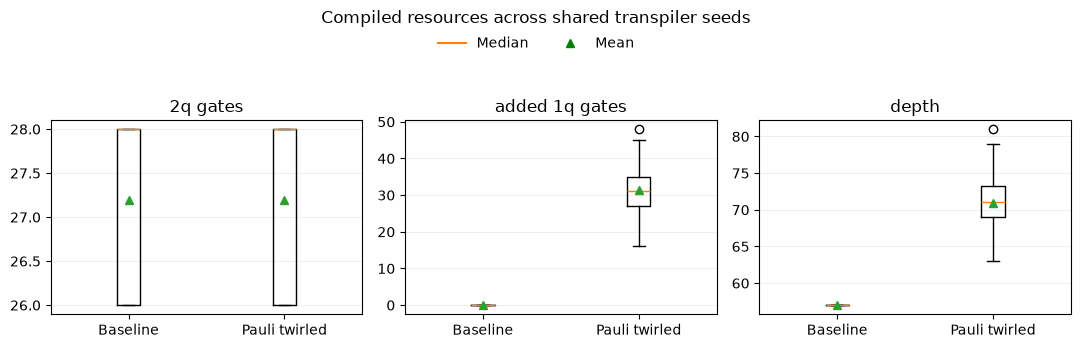

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, metric in zip(axes, ['2q gates', 'added 1q gates', 'depth']):
    data = [resource_table.loc[resource_table.method == name, metric]
            for name in ['Baseline', 'Pauli twirled']]
    ax.boxplot(data, tick_labels=['Baseline', 'Pauli twirled'], showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Compiled resources across shared transpiler seeds')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 5. Compare noisy samples with equal shot budgets

For each compilation seed and repeat, the baseline gets `shots` samples from one circuit. The twirled arm splits the same `shots` evenly across 16 randomized circuits, then combines their counts. This gives both arms equal total circuit shots, including the twirled ensemble's extra random circuits.

In [5]:
if backend.num_qubits > 16:
    raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')

simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
noisy_rows = []
for seed in noise_seeds:
    for repeat in range(noise_repeats):
        base_counts = simulator.run(
            compiled[seed],
            shots=shots,
            seed_simulator=90_000 + seed * 100 + repeat,
        ).result().get_counts()
        noisy_rows.append({
            'method': 'Baseline', 'seed': seed, 'repeat': repeat,
            'shots': shots, **score(base_counts),
        })

        variants = pauli_twirl_2q_gates(
            compiled[seed],
            seed=80_000 + seed * 100 + repeat,
            num_twirls=num_randomizations,
            target=backend.target,
        )
        results = simulator.run(
            variants,
            shots=shots_per_randomization,
            seed_simulator=91_000 + seed * 100 + repeat,
        ).result()
        pooled_counts = {}
        for counts in results.get_counts():
            for bitstring, count in counts.items():
                pooled_counts[bitstring] = pooled_counts.get(bitstring, 0) + count
        noisy_rows.append({
            'method': 'Pauli twirled', 'seed': seed, 'repeat': repeat,
            'shots': sum(pooled_counts.values()), **score(pooled_counts),
        })

noisy_results = pd.DataFrame(noisy_rows)
display(noisy_results.groupby('method', sort=False)[
    ['shots', 'mean cost', 'optimum frequency']
].agg(['mean', 'std']))

shots      mean cost           optimum frequency         
                 mean  std      mean       std              mean      std
method                                                                   
Baseline       2048.0  0.0  9.431424  0.123323          0.285482  0.00998
Pauli twirled  2048.0  0.0  9.477865  0.184606          0.282661  0.00957

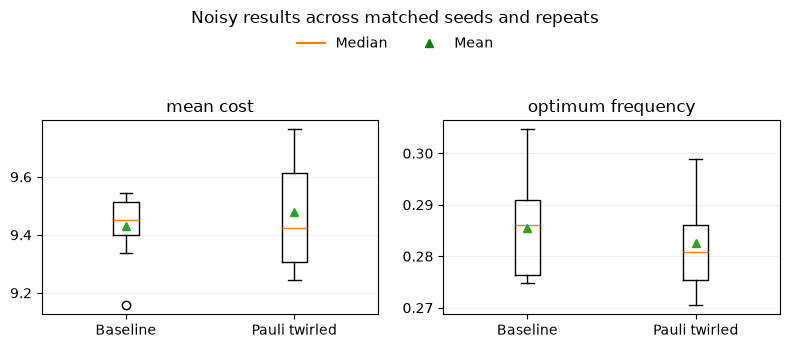

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
    data = [noisy_results.loc[noisy_results.method == name, metric]
            for name in ['Baseline', 'Pauli twirled']]
    ax.boxplot(data, tick_labels=['Baseline', 'Pauli twirled'], showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Noisy results across matched seeds and repeats')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## What did I find?

Baseline mean cost and optimum frequency were **9.43 ± 0.12** and **0.285 ± 0.010**. With Pauli twirling they were **9.48 ± 0.18** and **0.283 ± 0.010**. The 16-circuit twirl added a median of 31 single-qubit gates and raised median depth from 57 to 71. This pilot shows no improvement; twirling may still help when coherent errors dominate, which this FakeManilaV2 snapshot may not capture. A second backend is reserved for later.

In [7]:
summary = noisy_results.groupby('method')[['mean cost', 'optimum frequency']].mean()
cost_change = summary.loc['Pauli twirled', 'mean cost'] - summary.loc['Baseline', 'mean cost']
frequency_change = (summary.loc['Pauli twirled', 'optimum frequency']
                    - summary.loc['Baseline', 'optimum frequency'])
print(f'Mean-cost change (twirled − baseline): {cost_change:+.3f}')
print(f'Optimum-frequency change (twirled − baseline): {frequency_change:+.3f}')
print('Positive mean-cost change is worse; positive optimum-frequency change is better.')

Mean-cost change (twirled − baseline): +0.046
Optimum-frequency change (twirled − baseline): -0.003
Positive mean-cost change is worse; positive optimum-frequency change is better.


### References

- [IBM Quantum: Error suppression and Pauli twirling](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques) — what twirling changes and why it is usually applied to native two-qubit gates.
- [Qiskit API: `pauli_twirl_2q_gates`](https://qiskit.qotlabs.org/docs/api/qiskit/circuit) — supported gates, random circuit generation and backend-target synthesis. This notebook uses the installed Qiskit 2.5 API.
- [Wallman and Emerson, *Noise tailoring for scalable quantum computation via randomized compiling*](https://doi.org/10.1103/PhysRevA.94.052325) — the research basis for randomized compiling.